# Self-RAG over the Orbitra knowledge base - Stage 5 + hybrid search

Notebook version of `main.py`, split into sections. Run the cells top to bottom.
Retrieval is hybrid: vector + BM25 keyword search, merged with RRF, then reranked by a cross-encoder.

```
question -> decide_retrieval -> (yes) plan_queries -> retrieve -> grade_documents
                             -> (no)  generate_direct -> answer
grade_documents -> (some relevant) generate -> check_support
                -> (none relevant, rewrite left) rewrite_query -> retrieve
                -> (none relevant, no rewrite left) suggest_contact -> answer
check_support -> (fully supported) check_useful
              -> (not supported, retry left) revise_answer -> check_support
              -> (not supported, no retry left) flag_unsupported -> answer
check_useful -> (useful) answer
             -> (not useful, rewrite left) rewrite_query -> retrieve
             -> (not useful, no rewrite left) suggest_contact -> answer
```

## Setup: imports, `.env`, paths

In [1]:
import re
from pathlib import Path
from typing import Literal, TypedDict

import yaml
from dotenv import load_dotenv
from fastembed.rerank.cross_encoder import TextCrossEncoder
from langchain_chroma import Chroma
from langchain_community.embeddings import FastEmbedEmbeddings
from langchain_community.retrievers import BM25Retriever
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate
from langchain_groq import ChatGroq
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field

load_dotenv()

DOCS_DIR = Path("documents")
MODELS_DIR = "models"
CHROMA_DIR = "chroma_db"
COLLECTION = "orbitra_kb"

/media/kmh/New Volume/GenAICampusX/LangGraph/SelfRAG/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_71318/1578212635.py:9: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.embeddings import FastEmbedEmbeddings


## 1. Load the documents
Each `.md` file's YAML front-matter (`doc_id`, `status`, `applies_to`, ...) becomes the chunk's metadata.

In [2]:
# load the documents and parse the YAML header functions
def parse_markdown(path: Path) -> Document:
    """Read one .md file and turn its YAML front-matter into metadata."""
    text = path.read_text(encoding="utf-8")
    metadata = {"source": str(path)}

    if text.startswith("---"):
        _, front_matter, text = text.split("---", 2)
        try:
            header = yaml.safe_load(front_matter)
        except yaml.YAMLError:
            # e.g. HR-POSH-001 has an unquoted ": " inside a value, so read plain "key: value" lines
            lines = [line.split(":", 1) for line in front_matter.strip().splitlines() if ":" in line]
            header = {k.strip(): v.strip() for k, v in lines}
        for key, value in header.items():
            if value is None:
                continue
            # Chroma only stores str/int/float/bool, so flatten lists and dates
            if isinstance(value, list):
                value = ", ".join(map(str, value))
            elif not isinstance(value, (str, int, float, bool)):
                value = str(value)
            metadata[key] = value

    return Document(page_content=text.strip(), metadata=metadata)


def load_documents() -> list[Document]:
    return [parse_markdown(p) for p in sorted(DOCS_DIR.rglob("*.md"))]

splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=150)

## 2. Embeddings and vectorstore
The chunks are built once per run and shared with BM25; vectors are stored in `chroma_db/`. Small `batch_size` keeps RAM low.

In [3]:
# ONNX model, downloaded into models/ on the first run (bge vectors come out normalized).
# batch_size: default is 256, which needs >1.5 GB RAM for these chunks and froze the laptop.
embeddings = FastEmbedEmbeddings(model_name="BAAI/bge-small-en-v1.5", cache_dir=MODELS_DIR, batch_size=16)


# embeddings and the vectorstore (build once, and then load)
def get_vectorstore(chunks: list[Document]) -> Chroma:
    """Load the saved Chroma DB, or (re)build it if it is missing or incomplete."""
    vectorstore = Chroma(
        collection_name=COLLECTION,
        embedding_function=embeddings,
        persist_directory=CHROMA_DIR,
    )

    # fewer chunks than expected means first run, or an earlier build crashed halfway
    stored = len(vectorstore.get(include=[])["ids"])
    if stored == len(chunks):
        return vectorstore
    if stored:
        print(f"Vectorstore is incomplete ({stored}/{len(chunks)} chunks), rebuilding...")
        vectorstore.reset_collection()

    print(f"Building vectorstore from {len(chunks)} chunks...")
    step = embeddings.batch_size
    for i in range(0, len(chunks), step):
        vectorstore.add_documents(chunks[i:i + step])
        print(f"\r  embedded {min(i + step, len(chunks))}/{len(chunks)} chunks", end="", flush=True)
    print()
    return vectorstore


chunks = splitter.split_documents(load_documents())
vectorstore = get_vectorstore(chunks)

## 3. Hybrid search: vector + BM25, RRF merge, cross-encoder rerank
Vector search finds paraphrases; BM25 finds exact words ("comp-off"). RRF merges the two rankings by rank, then the jina cross-encoder reads the query with each of the 12 candidates and keeps the best 4.

In [4]:
# hybrid search: vector + BM25 keyword candidates, merged with RRF, then reranked
# keyword search catches exact words like "comp-off" that the embedding model misses
def tokenize(text: str) -> list[str]:
    return re.findall(r"\w+", text.lower())


CANDIDATES = 12
TOP_K = 4
vector_retriever = vectorstore.as_retriever(search_kwargs={"k": CANDIDATES})
bm25_retriever = BM25Retriever.from_documents(chunks, k=CANDIDATES, preprocess_func=tokenize)

# a cross-encoder reads the query and each chunk together, so it judges relevance much better
# than comparing two separate embeddings; ~130 MB ONNX model, downloaded into models/
reranker = TextCrossEncoder("jinaai/jina-reranker-v1-turbo-en", cache_dir=MODELS_DIR)


def reciprocal_rank_fusion(*ranked_lists: list[Document], k: int = 60) -> list[Document]:
    """Merge rankings: a chunk scores 1/(k + rank) in every list it appears in."""
    scores, docs = {}, {}
    for ranked in ranked_lists:
        for rank, doc in enumerate(ranked, 1):
            key = (doc.metadata["source"], doc.page_content)
            scores[key] = scores.get(key, 0) + 1 / (k + rank)
            docs[key] = doc
    return [docs[key] for key in sorted(scores, key=scores.get, reverse=True)]


def hybrid_search(query: str, top_k: int = TOP_K) -> list[Document]:
    candidates = reciprocal_rank_fusion(vector_retriever.invoke(query), bm25_retriever.invoke(query))[:CANDIDATES]
    scores = reranker.rerank(query, [d.page_content for d in candidates], batch_size=4)
    ranked = sorted(zip(scores, candidates), key=lambda pair: pair[0], reverse=True)
    return [doc for _, doc in ranked[:top_k]]

## 4. LLMs and the answer prompt
`llm` writes answers; `judge_llm` (low reasoning effort) makes the yes/no judgments.

In [5]:
# llm and prompt
# max_retries: on a 429 (free tier is 8000 tokens/min) the client waits as Groq says, then retries
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_retries=6)
# yes/no judgments don't need deep thinking; fewer reasoning tokens = fewer rate-limit hits.
# set on the model itself: llm.bind(reasoning_effort=...) is dropped by with_structured_output
judge_llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0, max_retries=6, reasoning_effort="low")

prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are OrbitBot, an internal assistant for Orbitra Technologies employees. "
     "Answer the question using only the context below. Give the direct answer first, "
     "then the conditions, exceptions and next steps the context gives for it (e.g. who "
     "must approve, deadlines, what is not allowed, what to do if it doesn't work), one "
     "short line each; leave out details about other topics. If the context does not "
     "contain the answer, say you don't know. If the answer depends on details the "
     "user did not give (location, level, etc.), list the options from the context "
     "and ask which applies. Cite the doc_id of every source you use, like "
     "[HR-LV-001].\n\nContext:\n{context}"),
    ("human", "{question}"),
])

def format_docs(docs: list[Document]) -> str:
    return "\n\n".join(f"[{d.metadata.get('doc_id', '?')}] {d.page_content}" for d in docs)

## 5. Stage 2 - retrieval decision (Self-RAG *Retrieve*)
Structured output: the LLM returns a `RetrievalDecision` object, not free text.
`planner` splits a multi-part question (e.g. a date question needs the deployment rules and the holiday calendar) into 1-3 sub-questions; `retrieve` runs one search per part.

In [6]:
# retrieval decision (Self-RAG's "Retrieve" step), returned as a Pydantic object
class RetrievalDecision(BaseModel):
    """Decide whether the question needs Orbitra's knowledge base."""
    should_retrieve: bool = Field(description="True if answering needs Orbitra's internal documents "
        "(policies, processes, people, products, company facts); False for greetings, small talk, "
        "or general knowledge unrelated to Orbitra.")
    reason: str = Field(description="One short sentence explaining the decision.")


decide_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You decide whether a question to OrbitBot, the internal assistant of Orbitra Technologies, "
     "needs a search of the company knowledge base (HR, IT, security, finance, admin, legal, "
     "engineering, product and sales documents). Retrieve for anything about Orbitra or how things "
     "work there, even if it sounds general (e.g. 'how do I reset my password?'). Do not retrieve "
     "for greetings, thanks, small talk, or general knowledge unrelated to Orbitra. When unsure, retrieve."),
    ("human", "{question}"),
])
decider = decide_prompt | judge_llm.with_structured_output(RetrievalDecision)

direct_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are OrbitBot, an internal assistant for Orbitra Technologies employees. Answer briefly. "
     "This question was judged not to need company documents, so do not state any Orbitra-specific "
     "facts or policies; if the user needs those, suggest they ask about them directly."),
    ("human", "{question}"),
])


# query planning: split a question into the separate facts it needs (one search each)
class QueryPlan(BaseModel):
    """The searches needed to answer the question."""
    sub_questions: list[str] = Field(description="1 to 3 standalone search questions: just the original "
        "question if one policy answers it; more only when the answer needs facts from different policies.")


plan_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You plan searches over Orbitra's internal knowledge base (HR, IT, security, finance, admin, legal, "
     "engineering, product and sales policies). Most questions need one fact: return the question "
     "unchanged as the only item. Split only when the answer needs facts that sit in different policies, "
     "for example:\n"
     "- whether something can happen on a date -> the rule for it (e.g. deployment windows and freezes) "
     "and the holiday calendar\n"
     "- an expense claim or purchase -> the spending limit and who approves it (the company approval matrix)\n"
     "- when a bonus or reimbursement will be paid -> the rule for it and the payroll cut-off dates\n"
     "- resigning or leaving -> the notice period and leave encashment\n"
     "Keep the user's region and level in every sub-question; leave out their own amounts and calculations."),
    ("human", "{question}"),
])
planner = plan_prompt | judge_llm.with_structured_output(QueryPlan)

MAX_SUB_QUESTIONS = 3
TOP_K_PER_PART = 3   # chunks per sub-question when there are several (one question keeps TOP_K = 4)

## 6. Stage 3 - document grading (Self-RAG *IsRel*)
One `DocGrade` per retrieved chunk; the grader sees the chunk's metadata too.

In [7]:
# document grading (Self-RAG's "IsRel" step), one grade per retrieved chunk
class DocGrade(BaseModel):
    """Relevance grade for one retrieved chunk."""
    is_relevant: bool = Field(description="True if the chunk contains information that helps answer "
        "the question; False if it is off-topic, superseded, or for a different region or group "
        "than the question asks about.")
    reason: str = Field(description="One short sentence explaining the grade.")


grade_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You grade whether a chunk from Orbitra's knowledge base is relevant to an employee's question. "
     "Use the chunk's metadata: a chunk with status 'superseded' is never relevant, because a newer "
     "version exists. A chunk whose applies_to clearly excludes the region or group the question is "
     "about is not relevant. If the question names no region, any region can be relevant. Otherwise "
     "be lenient: the chunk only needs to contain part of the answer. If the question has several "
     "parts, a chunk that answers any one part is relevant."),
    ("human",
     "Question: {question}\nParts of the question: {parts}\n\nChunk metadata: doc_id={doc_id}, title={title}, status={status}, "
     "applies_to={applies_to}\n\nChunk:\n{chunk}"),
])
grader = grade_prompt | judge_llm.with_structured_output(DocGrade)

## 7. Stage 4 - support check (Self-RAG *IsSup*)
`SupportGrade` uses a `Literal` with three levels. If claims are unsupported, `revise_answer` edits the answer once (remove/correct only), then it is checked again.

In [8]:
# support check (Self-RAG's "IsSup" step): is the answer grounded in the chunks?
class SupportGrade(BaseModel):
    """How well the retrieved chunks support the generated answer."""
    support: Literal["fully", "partially", "none"] = Field(description="'fully' if every factual "
        "claim in the answer is stated in, or directly calculated from, the chunks; 'partially' if "
        "some claims are not; 'none' if the answer is mostly unsupported.")
    unsupported_claims: list[str] = Field(description="Each claim not backed by the chunks; "
        "empty if fully supported.")


support_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You check whether an answer from OrbitBot is grounded in the retrieved chunks from Orbitra's "
     "knowledge base. A claim is supported if a chunk states it, if the user stated it in their "
     "question (e.g. their own salary, dates or counts), or if it is a direct calculation or "
     "rewording of those. Saying 'I don't know', asking the user a clarifying question, and "
     "citations like [HR-LV-001] are not claims. Anything else, such as numbers, names, rules or "
     "steps not found in the chunks or the question, is unsupported.\n\nChunks:\n{context}"),
    ("human", "Question: {question}\n\nAnswer to check:\n{answer}"),
])
support_checker = support_prompt | judge_llm.with_structured_output(SupportGrade)

# used when the support check fails: edit the previous answer instead of starting over
revise_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You are OrbitBot, an internal assistant for Orbitra Technologies employees. Your previous "
     "answer contained claims that the context does not support. Remove or correct only those "
     "claims and keep the rest of the answer as it was. Do not add any new details, even ones that "
     "seem helpful. Keep the doc_id citations like [HR-LV-001].\n\nContext:\n{context}"),
    ("human", "Question: {question}\n\nPrevious answer:\n{answer}\n\nUnsupported claims:\n{claims}"),
])

MAX_GENERATIONS = 2   # first answer + one revision

## 8. Stage 5 - usefulness check (Self-RAG *IsUse*) and query rewriting
`check_useful` asks if the answer addresses the question. When it doesn't, or when no chunk was relevant, `rewrite_query` writes a new search query (without the user's own numbers) for `retrieve` only; grading and generation still use the original question.
`contact_picker` picks the retrieved document whose owner is the best contact when nothing answers the question; `suggest_contact` takes the email from that document's metadata.

In [9]:
# usefulness check (Self-RAG's "IsUse" step): does the answer address the question?
class UsefulnessGrade(BaseModel):
    """Whether the answer actually addresses the user's question."""
    is_useful: bool = Field(description="True if the answer gives the user what they asked for, or asks "
        "a clarifying question with the options from the documents; False if it says the information "
        "is not available or answers a different question.")
    reason: str = Field(description="One short sentence explaining the grade.")


useful_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You check whether OrbitBot's answer is useful to the employee who asked the question. Judge only "
     "whether it addresses what was asked, not whether it is correct; correctness was already checked."),
    ("human", "Question: {question}\n\nAnswer:\n{answer}"),
])
usefulness_checker = useful_prompt | judge_llm.with_structured_output(UsefulnessGrade)

# query rewriting: a new search query for retrieve only; grading and generation keep the original question
rewrite_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "You rewrite an employee's question into a search query for Orbitra's internal knowledge base "
     "(HR, IT, finance, admin, legal, engineering policies). The search is semantic, over policy "
     "documents. Never copy the user's own amounts, salaries, counts or dates into the query, and "
     "drop any calculation; keep the region/location; use the words a "
     "policy document would use (e.g. 'entitlement', 'leave types', 'notice period'). "
     "Return only the query."),
    ("human", "Question: {question}\n\nThis search query did not find the answer: {previous_query}"),
])
rewriter = rewrite_prompt | judge_llm

MAX_REWRITES = 1


# when the knowledge base can't answer: point to the owner of the closest document (from its metadata)
class ContactChoice(BaseModel):
    """Pick the document whose owning team can best help with the question."""
    doc_id: str | None = Field(description="doc_id of the retrieved document closest in topic to the "
        "question, so its owner can help; None if none of them is about the same topic.")


contact_prompt = ChatPromptTemplate.from_messages([
    ("system",
     "OrbitBot could not answer an employee's question from Orbitra's knowledge base. From the "
     "documents that were retrieved, pick the one whose owning team is the best contact for this "
     "question (same topic, e.g. benefits, leave, IT access). Pick None if none is about the same topic."),
    ("human", "Question: {question}\n\nRetrieved documents:\n{documents}"),
])
contact_picker = contact_prompt | judge_llm.with_structured_output(ContactChoice)

## 9. Graph state, nodes and routers
Nodes return state updates; routers only read the state and name the next node.

In [10]:
# the graph(state,nodes,edges)
class GraphState(TypedDict):
    question: str
    should_retrieve: bool
    retrieval_reason: str
    documents: list[Document]
    doc_grades: list[dict]
    answer: str
    generation_attempts: int
    support: str
    unsupported_claims: list[str]
    sub_questions: list[str]  # from plan_queries: one search per part
    search_query: str  # set by a rewrite; retrieve then searches only this
    rewrite_count: int
    is_useful: bool
    usefulness_reason: str


def decide_retrieval(state: GraphState) -> dict:
    decision = decider.invoke({"question": state["question"]})
    return {"should_retrieve": decision.should_retrieve, "retrieval_reason": decision.reason}


# router, not a node: only reads the state and names the next node
def route_after_decision(state: GraphState) -> Literal["plan_queries", "generate_direct"]:
    return "plan_queries" if state["should_retrieve"] else "generate_direct"


def plan_queries(state: GraphState) -> dict:
    plan = planner.invoke({"question": state["question"]})
    return {"sub_questions": plan.sub_questions[:MAX_SUB_QUESTIONS] or [state["question"]]}


def retrieve(state: GraphState) -> dict:
    # after a rewrite: one new query; otherwise one search per sub-question
    queries = [state["search_query"]] if state.get("search_query") else state["sub_questions"]
    k = TOP_K if len(queries) == 1 else TOP_K_PER_PART
    docs, seen = [], set()
    for query in queries:
        for d in hybrid_search(query, k):
            key = (d.metadata["source"], d.page_content)   # the same chunk can come back for two parts
            if key not in seen:
                seen.add(key)
                docs.append(d)
    return {"documents": docs}


def grade_documents(state: GraphState) -> dict:
    docs = state["documents"]
    grades = grader.batch([
        {"question": state["question"], "parts": "; ".join(state["sub_questions"]), "chunk": d.page_content,
         **{k: d.metadata.get(k, "?") for k in ("doc_id", "title", "status", "applies_to")}}
        for d in docs
    ])  # one LLM call per chunk, sent in parallel
    # no reducer on "documents", so this filtered list replaces the one retrieve wrote
    return {
        "documents": [d for d, g in zip(docs, grades) if g.is_relevant],
        # title/department/owner: suggest_contact uses them when nothing answers the question
        "doc_grades": [{"doc_id": d.metadata.get("doc_id"), "relevant": g.is_relevant, "reason": g.reason,
                        **{k: d.metadata.get(k, "?") for k in ("title", "department", "owner")}}
                       for d, g in zip(docs, grades)],
    }


def route_after_grading(state: GraphState) -> Literal["generate", "rewrite_query", "suggest_contact"]:
    if state["documents"]:
        return "generate"
    if state.get("rewrite_count", 0) < MAX_REWRITES:
        return "rewrite_query"
    return "suggest_contact"


def suggest_contact(state: GraphState) -> dict:
    docs = {g["doc_id"]: g for g in state["doc_grades"]}   # one entry per document
    listing = "\n".join(f"- {g['doc_id']}: {g['title']} (team: {g['department']})" for g in docs.values())
    choice = contact_picker.invoke({"question": state["question"], "documents": listing})
    # the LLM only picks a doc_id; the email comes from the document's metadata, so it can't be made up
    contact = docs.get(choice.doc_id)
    tip = (f"The closest policy is {contact['title']} [{contact['doc_id']}], owned by "
           f"{contact['department']}: you can ask them at {contact['owner']}." if contact else
           "Try rephrasing, or raise an OrbitDesk ticket with the relevant team.")
    if state["documents"]:   # an answer was written but didn't help: keep it, add the contact
        return {"answer": state["answer"] + "\n\n" + tip}
    return {"answer": "I couldn't find an answer to this in the Orbitra knowledge base. " + tip}


def generate(state: GraphState) -> dict:
    chain = prompt | llm
    response = chain.invoke({
        "context": format_docs(state["documents"]),
        "question": state["question"],
    })
    return {"answer": response.content, "generation_attempts": 1}


def revise_answer(state: GraphState) -> dict:
    claims = "\n".join(f"- {c}" for c in state["unsupported_claims"])
    response = (revise_prompt | llm).invoke({
        "context": format_docs(state["documents"]),
        "question": state["question"],
        "answer": state["answer"],
        "claims": claims,
    })
    return {"answer": response.content, "generation_attempts": state["generation_attempts"] + 1}


def check_support(state: GraphState) -> dict:
    grade = support_checker.invoke({
        "context": format_docs(state["documents"]),
        "question": state["question"],  # the user's own numbers are valid inputs to the answer
        "answer": state["answer"],
    })
    return {"support": grade.support, "unsupported_claims": grade.unsupported_claims}


# END is just the string "__end__", so a router can finish the graph directly
def route_after_support(state: GraphState) -> Literal["check_useful", "revise_answer", "flag_unsupported"]:
    if state["support"] == "fully":
        return "check_useful"
    if state["generation_attempts"] < MAX_GENERATIONS:
        return "revise_answer"
    return "flag_unsupported"


def flag_unsupported(state: GraphState) -> dict:
    claims = "\n".join(f"- {c}" for c in state["unsupported_claims"])
    return {"answer": state["answer"] + "\n\n⚠️ I couldn't verify these parts against the "
                                        "knowledge base:\n" + claims}


def check_useful(state: GraphState) -> dict:
    grade = usefulness_checker.invoke({"question": state["question"], "answer": state["answer"]})
    return {"is_useful": grade.is_useful, "usefulness_reason": grade.reason}


# not useful after the rewrite (e.g. "I don't know"): point the user to a contact instead
def route_after_useful(state: GraphState) -> Literal["__end__", "rewrite_query", "suggest_contact"]:
    if state["is_useful"]:
        return END
    if state.get("rewrite_count", 0) < MAX_REWRITES:
        return "rewrite_query"
    return "suggest_contact"


def rewrite_query(state: GraphState) -> dict:
    new_query = rewriter.invoke({
        "question": state["question"],
        "previous_query": state.get("search_query") or state["question"],
    }).content.strip()
    return {"search_query": new_query, "rewrite_count": state.get("rewrite_count", 0) + 1}


def generate_direct(state: GraphState) -> dict:
    response = (direct_prompt | llm).invoke({"question": state["question"]})
    return {"answer": response.content}

## 10. Build the graph

In [11]:
builder = StateGraph(GraphState)
builder.add_node("decide_retrieval", decide_retrieval)
builder.add_node("plan_queries", plan_queries)
builder.add_node("retrieve", retrieve)
builder.add_node("grade_documents", grade_documents)
builder.add_node("generate", generate)
builder.add_node("check_support", check_support)
builder.add_node("revise_answer", revise_answer)
builder.add_node("flag_unsupported", flag_unsupported)
builder.add_node("check_useful", check_useful)
builder.add_node("rewrite_query", rewrite_query)
builder.add_node("suggest_contact", suggest_contact)
builder.add_node("generate_direct", generate_direct)
builder.add_edge(START, "decide_retrieval")
builder.add_conditional_edges("decide_retrieval", route_after_decision)
builder.add_edge("plan_queries", "retrieve")
builder.add_edge("retrieve", "grade_documents")
builder.add_conditional_edges("grade_documents", route_after_grading)
builder.add_edge("generate", "check_support")
builder.add_conditional_edges("check_support", route_after_support)
builder.add_edge("revise_answer", "check_support")
builder.add_conditional_edges("check_useful", route_after_useful)
builder.add_edge("rewrite_query", "retrieve")  # loop back with the new search query
builder.add_edge("flag_unsupported", END)
builder.add_edge("suggest_contact", END)
builder.add_edge("generate_direct", END)
app = builder.compile()

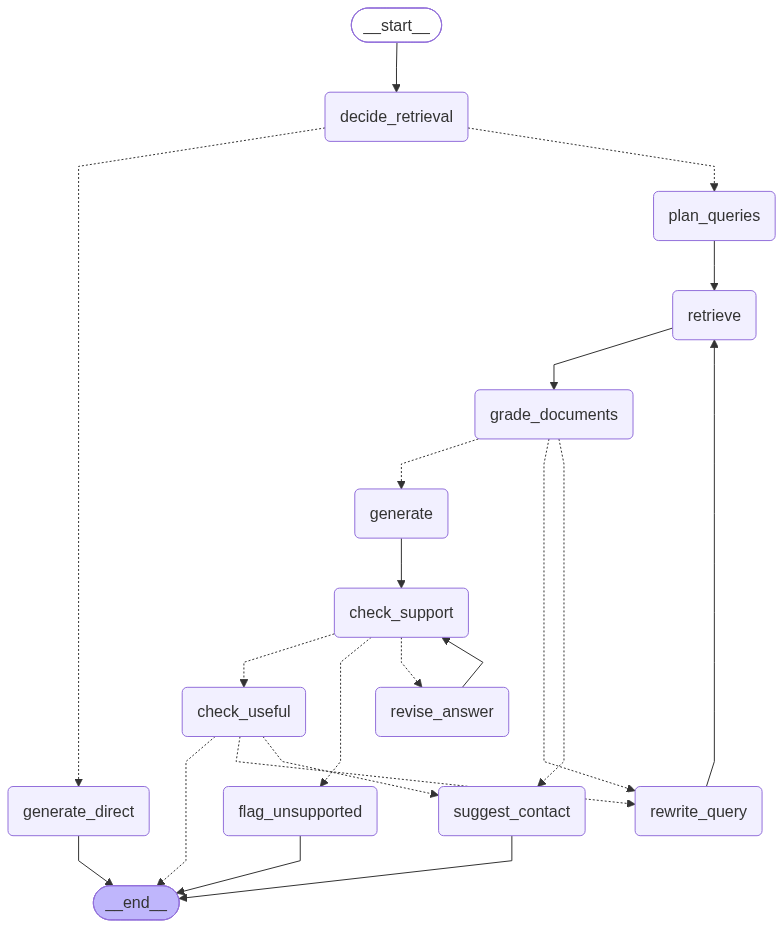

In [12]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))  # rendered by the mermaid.ink web service
except Exception:
    print(app.get_graph().draw_mermaid())  # offline fallback: paste into mermaid.live

## 11. Ask questions
`ask()` streams each node's update so you can watch the decision and the grades. (The interactive loop is in `main.py`: `uv run main.py`.)

In [13]:
def ask(question: str):
    for step in app.stream({"question": question}, stream_mode="updates"):
        for node, update in step.items():
            print(f"--- {node} ---")
            if node == "decide_retrieval":
                print(f"  retrieve={update['should_retrieve']}  ({update['retrieval_reason']})")
            elif node == "plan_queries":
                print(f"  🧩 parts: {update['sub_questions']}")
            elif node == "retrieve":
                for d in update["documents"]:
                    print(f"  [{d.metadata.get('doc_id')}] status={d.metadata.get('status')}  "
                          f"{d.page_content[:80]!r}")
            elif node == "grade_documents":
                for g in update["doc_grades"]:
                    print(f"  {'✓' if g['relevant'] else '✗'} [{g['doc_id']}] {g['reason']}")
            elif node == "check_support":
                print(f"  support={update['support']}")
                for c in update["unsupported_claims"]:
                    print(f"  ✗ {c}")
            elif node == "check_useful":
                print(f"  useful={update['is_useful']}  ({update['usefulness_reason']})")
            elif node == "rewrite_query":
                print(f"  🔁 new query: {update['search_query']!r}")
            else:
                print(update["answer"])

In [14]:
ask("hi")

--- decide_retrieval ---
  retrieve=False  (User greeting does not require internal knowledge.)
--- generate_direct ---
Hello! How can I help you today?


In [15]:
ask("Within how many days must I use a comp-off?")

--- decide_retrieval ---
  retrieve=True  (User asks about company policy for using compensatory off days, which is an HR internal policy.)
--- plan_queries ---
  🧩 parts: ['Within how many days must I use a comp-off?']
--- retrieve ---
  [HR-LV-001] status=active  '| Bereavement Leave | 5 working days (immediate family); 2 days (extended family'
  [HR-LV-001] status=superseded  '# Leave Policy – India (v4.0) — ARCHIVED / SUPERSEDED\n\n> ⚠️ This version is reta'
  [HR-LV-002] status=active  '## Parental leave\n- **16 weeks fully paid** for birthing parents (includes short'
  [HR-LV-001] status=active  '## 7. Leave encashment at exit\nAt exit, up to 30 days of EL balance is encashed '
--- grade_documents ---
  ✓ [HR-LV-001] Chunk specifies the comp-off must be used within 60 days, directly answering the question.
  ✗ [HR-LV-001] Chunk is superseded, so it cannot be used to answer current questions.
  ✓ [HR-LV-002] The chunk explains that comp-off does not exist for US employees, directl

In [16]:
ask("How many days of paternity leave can I take in Bengaluru?")

--- decide_retrieval ---
  retrieve=True  (User asks about paternity leave policy in Bengaluru, which is an internal HR policy requiring company knowledge.)
--- plan_queries ---
  🧩 parts: ["What is the paternity leave entitlement (in days) according to Orbitra's HR policy for employees in Bengaluru?", 'What are the statutory paternity leave requirements in Bengaluru, India that Orbitra must comply with?']
--- retrieve ---
  [HR-LV-001] status=active  '# Leave Policy – India (v5.0)\n\n> **What changed in v5.0 (effective 1 April 2026)'
  [HR-LV-001] status=superseded  '# Leave Policy – India (v4.0) — ARCHIVED / SUPERSEDED\n\n> ⚠️ This version is reta'
  [HR-POSH-001] status=active  '# POSH Policy\n\n## 1. Scope\nApplies to all Orbitra workplaces including offices, '
  [HR-LV-002] status=active  '## Parental leave\n- **16 weeks fully paid** for birthing parents (includes short'
  [HR-LV-003] status=active  '## Family leave\n- **Maternity / Adoption:** 26 weeks at full pay, followed by 13

In [17]:
ask("How many sick leaves do India employees get per year?")

--- decide_retrieval ---
  retrieve=True  (Question asks about specific company policy (sick leave entitlement) for employees in India, requiring internal HR documents.)
--- plan_queries ---
  🧩 parts: ['How many sick leaves do India employees get per year?']
--- retrieve ---
  [HR-LV-001] status=active  '## 2. Leave types and entitlement\n| Leave type | Entitlement per year | Accrual '
  [HR-LV-001] status=active  '## 7. Leave encashment at exit\nAt exit, up to 30 days of EL balance is encashed '
  [HR-LV-002] status=active  '## Parental leave\n- **16 weeks fully paid** for birthing parents (includes short'
  [HR-LV-002] status=active  '# PTO and Leave Policy – United States\n\n## PTO\n| Years of service | Annual PTO |'
--- grade_documents ---
  ✓ [HR-LV-001] Chunk provides the sick leave entitlement (12 days per year) for India employees, directly answering the question.
  ✗ [HR-LV-001] Chunk does not specify the number of sick leaves per year; it only mentions lapse and conversion d

In [18]:
ask("My Basic is INR 60,000 and HRA is INR 30,000 per month. How much would I pay to buy out 20 days of notice?")

--- decide_retrieval ---
  retrieve=True  (User asks about notice buyout calculation based on salary components, which is an HR policy question specific to Orbitra.)
--- plan_queries ---
  🧩 parts: ['What is the notice period and buyout policy for employees in India at my level?', 'How is the buyout amount for notice period calculated, i.e., which salary components (basic, HRA, etc.) are included?']
--- retrieve ---
  [HR-EXIT-001] status=active  '# Resignation and Exit Process\n\n## 1. Notice period\n| Category | Notice period |'
  [FIN-004] status=active  '# Corporate Card Policy\n\n## Eligibility\n- Employees at **L7 and above**, and\n- E'
  [HR-LV-001] status=active  '# Leave Policy – India (v5.0)\n\n> **What changed in v5.0 (effective 1 April 2026)'
  [HR-PAY-001] status=active  'Joiners who join after the 20th are paid for their partial month along with the '
  [HR-LV-001] status=active  '## 7. Leave encashment at exit\nAt exit, up to 30 days of EL balance is encashed '
--- grade

In [19]:
ask("I'm an L5 travelling Bengaluru to Delhi for 3 nights, flying out at 4 PM on day 1 and returning at 10 AM on day 4. What per diem can I claim?")

--- decide_retrieval ---
  retrieve=True  (User asks about per diem claim policy for travel, which is internal HR/finance information.)
--- plan_queries ---
  🧩 parts: ["What per diem amount can an L5 employee traveling from Bengaluru to Delhi for 3 nights (departing at 4 PM day 1, returning at 10 AM day 4) claim according to Orbitra's travel expense policy?"]
--- retrieve ---
  [FIN-002] status=active  '- Per diem is paid **without receipts**; claim in SpendWise → "Per diem" with tr'
  [FIN-002] status=active  '## 3. Hotel limits (per night, excluding taxes)\n| City tier | L1–L5 | L6–L7 | L8'
  [FIN-001] status=active  '## 4. Not reimbursable\nPersonal travel, traffic or parking fines, alcohol withou'
  [ADM-002] status=active  '# Employee Transport Policy – India\n\n## 1. Shuttle service (free)\n- **Metro shut'
--- grade_documents ---
  ✓ [FIN-002] Chunk provides per diem rules, including 50% for departure after 2 PM, directly answering the employee's claim amount question.
  ✓ [FIN-